In [164]:

from __future__ import print_function, division
from collections import defaultdict, OrderedDict
import gzip
import pickle
import json
import os
import uproot
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
from coffea import hist, processor 
from coffea.hist import plot
from coffea.util import load, save

In [165]:
hists = load('2D_lep_monotop_v1_2017.merged')

In [166]:
scale ={}
for d in hists['sumw'].identifiers('dataset'):
    scale[d]=hists['sumw'].integrate('dataset', d).values(overflow='all')[()][1]
print('Sumw extracted')

for key in hists.keys():
    if (key=='sumw'): continue
    for d in hists[key].identifiers('dataset'):
        if 'MET' in d.name or 'SingleElectron' in d.name or 'SinglePhoton' in d.name or 'EGamma' in d.name or 'SingleMuon' in d.name: continue
#         hists[key].scale({d:1/(scale[d]*3)},axis='dataset')
        hists[key].scale({d:1},axis='dataset')

Sumw extracted


In [161]:
bkg_hists['template_mt_dphi_met_lj']

<Hist (process,region,systematic,mT,dphi_Met_LJ) instance at 0x7f65e35331f0>

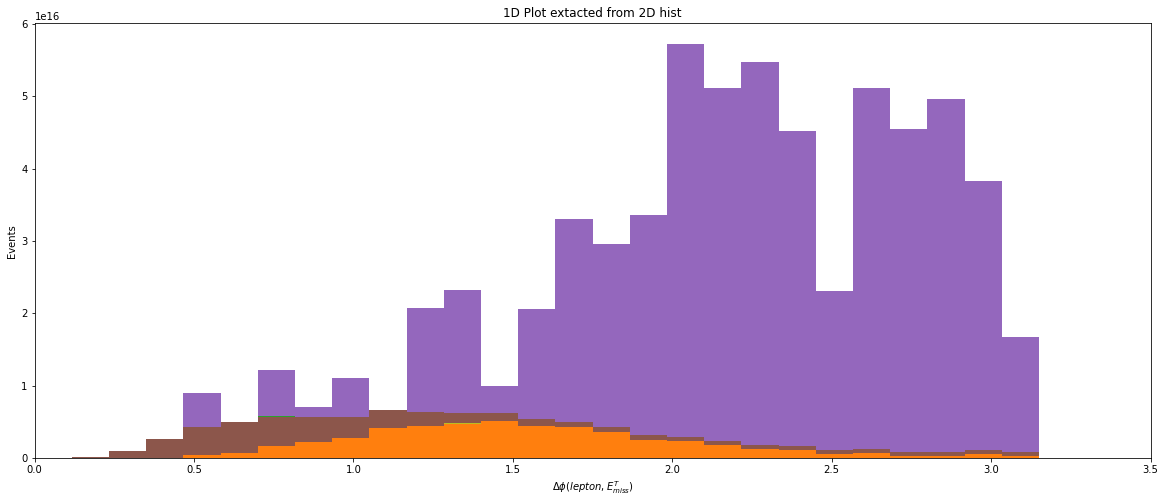

In [167]:
from matplotlib.pyplot import figure

fig, ax = plt.subplots(figsize=(20,8))
plot.plot1d(hists['template_mt_dphi_lep_etmiss'].integrate('region', 'wjete').integrate('systematic', 'nominal').integrate('mT')[()], stack=True)
plt.title("1D Plot extacted from 2D hist")
ax.get_legend().remove()

In [171]:
hists['template_mt_dphi_met_lj'].integrate('region', 'wjete').integrate('systematic', 'nominal').integrate('mT')[()].values().keys()

KeyError: 'No axis process found in <Hist (dataset,mT,dphi_Met_LJ) instance at 0x7f65e30cbd30>'

In [179]:
hists['dphi_e_etmiss'].integrate('region', 'wjete').integrate('dataset', p).values()[()]

array([       0.        , 13264260.98080314,  5802597.19285445,
       10658814.41308665,  9925703.82280825,  5496883.16488887,
       15476448.46129584,  7728852.83356286,  7390775.33650358,
       17627555.39388845, 27035517.6964651 ,        0.        ,
        6547483.55551664, 11136312.99700918, 17800659.41505117,
              0.        ,  5332197.82250013,  7983424.54370632,
         775599.20352484,  5689435.10016959,  4624038.77913535,
       12572471.81414402,  2354557.59342142,  9453733.65170196,
       18141121.3435325 ,  3112534.19788275,  6038158.27309469,
              0.        ,        0.        ,        0.        ])

In [180]:
for i in hists['template_mt_dphi_met_lj'].integrate('region', 'wjete').integrate('systematic', 'nominal').integrate('mT')[()].values().keys():
        p = str(i[0])
#         print(p)
        val = sum(hists['template_mt_dphi_met_lj'].integrate('region', 'wjete').integrate('systematic', 'nominal').integrate('dataset', p).integrate('mT').values()[()])
#         scale[i] = 1./3
        val2 = sum(hists['dphi_e_etmiss'].integrate('region', 'wjete').integrate('dataset', p).values()[()])
        print("template:",p,val)
        print(val2)

template: QCD_HT1500to2000_TuneCP5_13TeV-madgraph-pythia8 696316639.1993635
231969137.58654776
template: HF--WJetsToLNu_HT-800To1200_TuneCP5_13TeV-madgraphMLM-pythia8 399384728268.3661
13773867709.465126
template: LF--WJetsToLNu_HT-800To1200_TuneCP5_13TeV-madgraphMLM-pythia8 2308279389613.7256
79626215398.90022
template: SingleElectron 458869.0
458884.0
template: ZZ_TuneCP5_13TeV-pythia8 282720051.7874055
94220867.50378454
template: HF--WJetsToLNu_HT-100To200_TuneCP5_13TeV-madgraphMLM-pythia8 40580505169896.63
1399103154039.1663
template: LF--WJetsToLNu_HT-100To200_TuneCP5_13TeV-madgraphMLM-pythia8 158497704882594.56
5464638472947.201
template: QCD_HT200to300_TuneCP5_13TeV-madgraph-pythia8 0.0
0.0
template: QCD_HT700to1000_TuneCP5_13TeV-madgraph-pythia8 14664036739.3661
4886464976.600555
template: HF--WJetsToLNu_HT-400To600_TuneCP5_13TeV-madgraphMLM-pythia8 2851577576964.087
98331583071.87741
template: LF--WJetsToLNu_HT-400To600_TuneCP5_13TeV-madgraphMLM-pythia8 13967917957508.703
4817

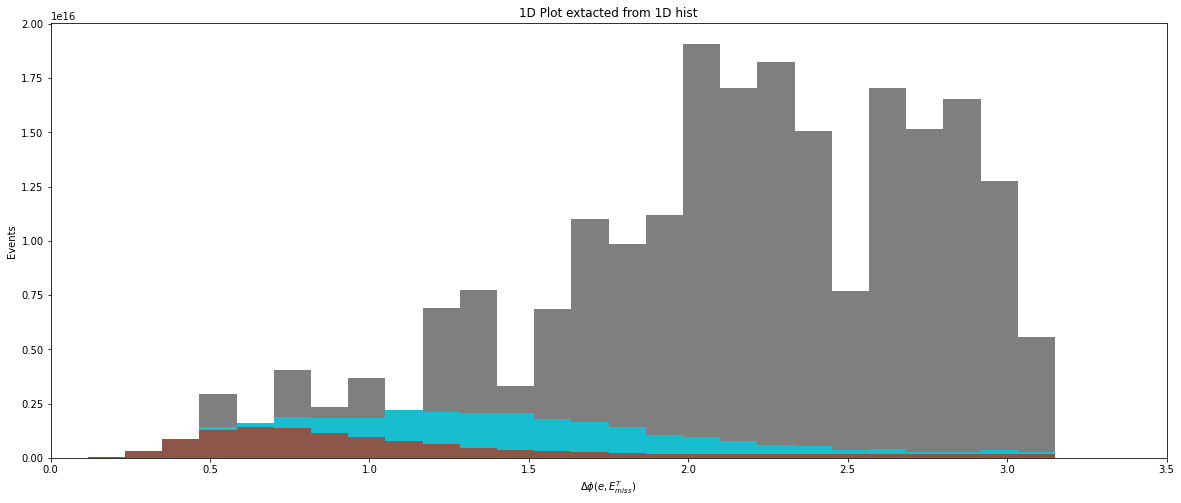

In [168]:
from matplotlib.pyplot import figure

fig, ax = plt.subplots(figsize=(20,8))
# figure(figsize=(25, 10), dpi=80)
plot.plot1d(hists['dphi_e_etmiss'].integrate('region', 'wjete'), overlay='dataset', stack=True)
plt.title("1D Plot extacted from 1D hist")
ax.get_legend().remove()

Text(0.5, 1.0, '1D Plot extacted from 1D hist')

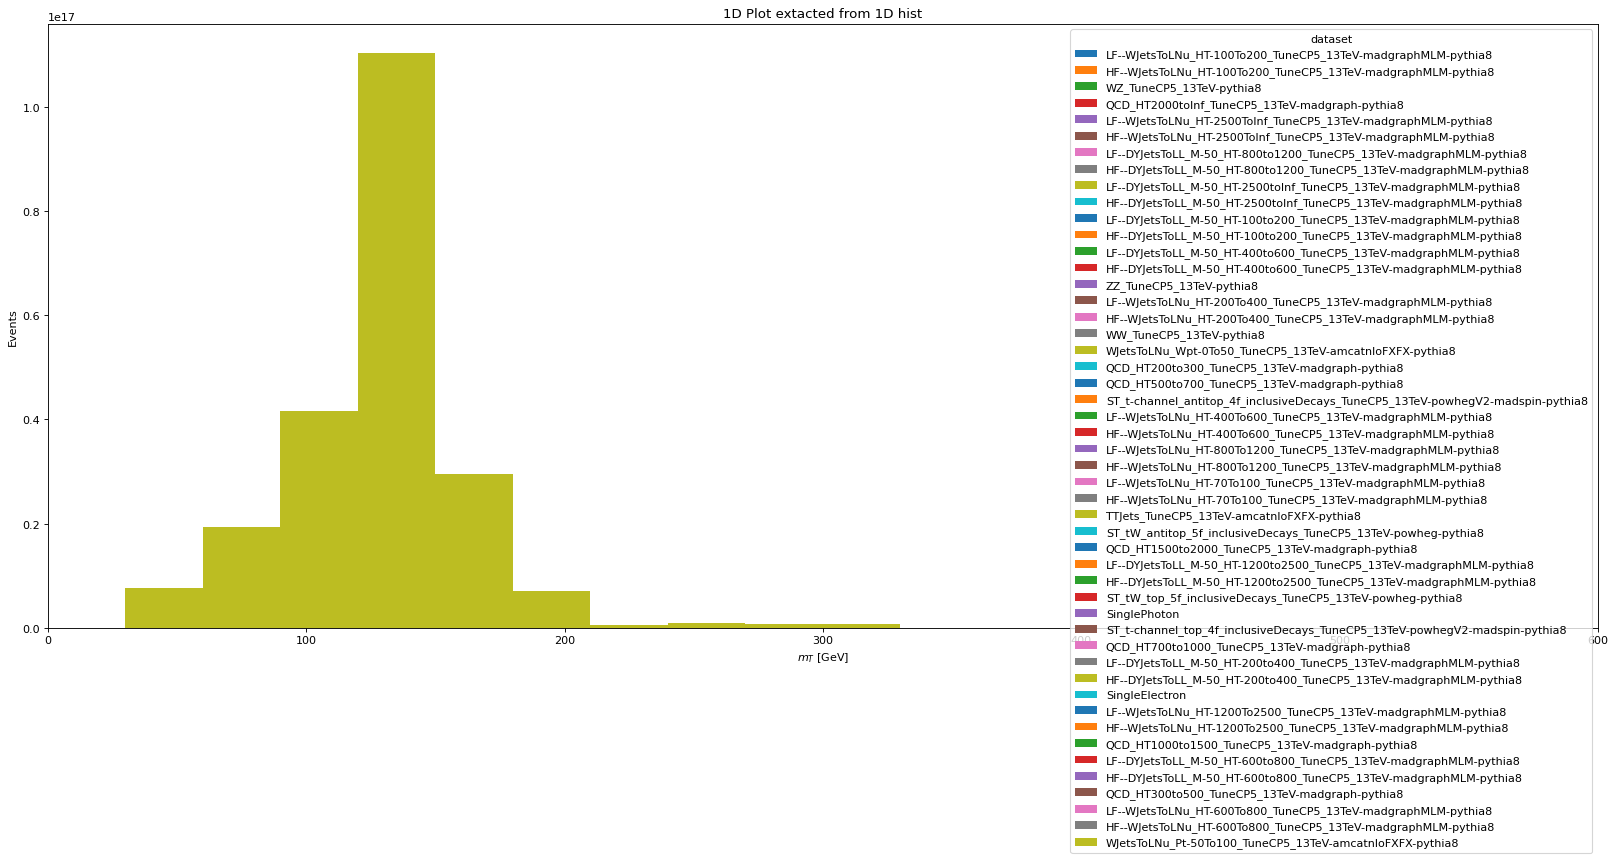

In [63]:
from matplotlib.pyplot import figure

figure(figsize=(25, 10), dpi=80)
plot.plot1d(hists['mT'].integrate('region', 'wjete'), overlay='dataset', stack=True)
plt.title("1D Plot extacted from 1D hist")